Q1 — Loading the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub
import glob
import os

path = kagglehub.dataset_download(
    "colabsss/student-academic-monitoring-dataset"
)

print(glob.glob(path + "/*"))

100%|██████████| 328k/328k [00:00<00:00, 496kB/s]

Extracting files...
['/root/.cache/kagglehub/datasets/colabsss/student-academic-monitoring-dataset/versions/3/Student_Dataset2.csv']


In [4]:
csv_files = glob.glob(path + "/*.csv")

print(csv_files)

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print(df.head())

['/root/.cache/kagglehub/datasets/colabsss/student-academic-monitoring-dataset/versions/3/Student_Dataset2.csv']
Dataset loaded successfully!
  Student_ID  Age  Gender Course_ID  Week  Assignment_Score  Quiz_Score  \
0     S00001   24    Male     ME303     1             97.17       35.87   
1     S00002   21    Male    ENG505    12             74.27       63.50   
2     S00003   28    Male     ME303    14             58.40       37.60   
3     S00004   25  Female     ME303    15             62.72       74.62   
4     S00005   22    Male    ECE202    15             82.89       74.55   

   Midterm_Score  Final_Score   GPA  ...  Study_Hours_Per_Week  \
0          53.54        49.00  4.61  ...                  4.40   
1          90.06        81.18  8.47  ...                 18.71   
2          40.69        72.06  6.81  ...                 12.00   
3          42.60        80.27  9.39  ...                  2.96   
4          45.73        63.02  6.14  ...                 14.18   

   Deadlin

Q2 — Inspecting the Dataset

In [5]:

# Q2 (a) - Dataset shape

print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset shape: (6834, 27)
Number of rows: 6834
Number of columns: 27


In [6]:

# Q2 (b) - Data types

print(df.dtypes)


Student_ID                           object
Age                                   int64
Gender                               object
Course_ID                            object
Week                                  int64
Assignment_Score                    float64
Quiz_Score                          float64
Midterm_Score                       float64
Final_Score                         float64
GPA                                 float64
LMS_Login_Frequency                   int64
Session_Duration                    float64
Video_Completion_Rate               float64
Forum_Participation_Count             int64
Assignment_Submission_Delay           int64
Attendance_Rate                     float64
Absence_Count                         int64
Study_Hours_Per_Week                float64
Deadline_Missed_Count                 int64
Peer_Interaction_Score              float64
Instructor_Interaction_Frequency      int64
Resource_Usage_Diversity            float64
Cognitive_Engagement_Index      

In [7]:

# Q2 (c) - First five rows

print(df.head())


  Student_ID  Age  Gender Course_ID  Week  Assignment_Score  Quiz_Score  \
0     S00001   24    Male     ME303     1             97.17       35.87   
1     S00002   21    Male    ENG505    12             74.27       63.50   
2     S00003   28    Male     ME303    14             58.40       37.60   
3     S00004   25  Female     ME303    15             62.72       74.62   
4     S00005   22    Male    ECE202    15             82.89       74.55   

   Midterm_Score  Final_Score   GPA  ...  Study_Hours_Per_Week  \
0          53.54        49.00  4.61  ...                  4.40   
1          90.06        81.18  8.47  ...                 18.71   
2          40.69        72.06  6.81  ...                 12.00   
3          42.60        80.27  9.39  ...                  2.96   
4          45.73        63.02  6.14  ...                 14.18   

   Deadline_Missed_Count  Peer_Interaction_Score  \
0                      1                    7.56   
1                      4                    6.11

In [8]:

# Q2 (d) - Numeric summary statistics

print(df.describe())


               Age         Week  Assignment_Score   Quiz_Score  Midterm_Score  \
count  6834.000000  6834.000000       6834.000000  6834.000000    6834.000000   
mean     23.506438     7.976149         69.885135    67.980278      64.532091   
std       3.464275     4.329153         17.342803    18.760187      20.205538   
min      18.000000     1.000000         40.000000    35.000000      30.010000   
25%      20.000000     4.000000         54.760000    52.020000      47.112500   
50%      23.000000     8.000000         69.580000    68.340000      64.525000   
75%      27.000000    12.000000         84.957500    84.237500      81.992500   
max      29.000000    15.000000         99.990000   100.000000      99.990000   

       Final_Score          GPA  LMS_Login_Frequency  Session_Duration  \
count  6834.000000  6834.000000          6834.000000       6834.000000   
mean     65.255309     7.006045            12.484636         95.421260   
std      20.257173     1.721385             6.88

In [9]:

# Q2 (e) - Non-numeric summary statistics

print(df.describe(include="object"))


       Student_ID Gender Course_ID Academic_Status
count        6834   6834      6834            6834
unique       6834      2         5               3
top        S06834   Male    ECE202       Attention
freq            1   3447      1412            4580


In [10]:

# Q2 (f) - Numeric and categorical columns

num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns:")
print(num_cols)

print("\nCategorical columns:")
print(cat_cols)


Numeric columns:
['Age', 'Week', 'Assignment_Score', 'Quiz_Score', 'Midterm_Score', 'Final_Score', 'GPA', 'LMS_Login_Frequency', 'Session_Duration', 'Video_Completion_Rate', 'Forum_Participation_Count', 'Assignment_Submission_Delay', 'Attendance_Rate', 'Absence_Count', 'Study_Hours_Per_Week', 'Deadline_Missed_Count', 'Peer_Interaction_Score', 'Instructor_Interaction_Frequency', 'Resource_Usage_Diversity', 'Cognitive_Engagement_Index', 'Risk_Index', 'Performance_Trend', 'Consistency_Index']

Categorical columns:
['Student_ID', 'Gender', 'Course_ID', 'Academic_Status']


In [11]:

# Q2 - Largest standard deviation

std_values = df[num_cols].std().dropna()

if not std_values.empty:
    print("Column with largest standard deviation:",
          std_values.idxmax())
    print("Standard deviation:", std_values.max())
else:
    print("No suitable numeric columns found.")


Column with largest standard deviation: Session_Duration
Standard deviation: 49.012624077772955


a) How many rows and columns does the dataset have?

The dataset contains 6,834 rows and 27 columns.

b) Which columns are numeric and which are categorical?

The dataset contains 23 numeric columns and 4 categorical columns.

The numeric columns are: Age, Week, Assignment_Score, Quiz_Score, Midterm_Score, Final_Score, GPA, LMS_Login_Frequency, Session_Duration, Video_Completion_Rate, Forum_Participation_Count, Assignment_Submission_Delay, Attendance_Rate, Absence_Count, Study_Hours_Per_Week, Deadline_Missed_Count, Peer_Interaction_Score, Instructor_Interaction_Frequency, Resource_Usage_Diversity, Cognitive_Engagement_Index, Risk_Index, Performance_Trend, and Consistency_Index.

The categorical columns are: Student_ID, Gender, Course_ID, and Academic_Status.

c) Which numeric column has the largest standard deviation?

The column Session_Duration has the largest standard deviation, with a value of approximately 49.01. This indicates that session durations have the greatest absolute spread around their mean among the numeric columns. The mean session duration is approximately 95.42, showing that students' session durations vary considerably within the dataset.

Q3 - DATA QUALITY CHECKS

In [12]:
print("\n" + "=" * 60)
print("Q3 - DATA QUALITY CHECKS")
print("=" * 60)

# a) Missing values
print("\n(a) Missing values in each column:")
print(df.isnull().sum())

# b) Duplicate rows
print("\n(b) Number of duplicate rows:")
print(df.duplicated().sum())

# c) Unique values in categorical columns
print("\n(c) Unique values in categorical columns:")
for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].unique())

# d) Minimum and maximum of numeric columns
print("\n(d) Minimum and maximum of numeric columns:")
if num_cols:
    print(df[num_cols].agg(["min", "max"]).T)
else:
    print("No numeric columns were found.")


Q3 - DATA QUALITY CHECKS

(a) Missing values in each column:
Student_ID                          0
Age                                 0
Gender                              0
Course_ID                           0
Week                                0
Assignment_Score                    0
Quiz_Score                          0
Midterm_Score                       0
Final_Score                         0
GPA                                 0
LMS_Login_Frequency                 0
Session_Duration                    0
Video_Completion_Rate               0
Forum_Participation_Count           0
Assignment_Submission_Delay         0
Attendance_Rate                     0
Absence_Count                       0
Study_Hours_Per_Week                0
Deadline_Missed_Count               0
Peer_Interaction_Score              0
Instructor_Interaction_Frequency    0
Resource_Usage_Diversity            0
Cognitive_Engagement_Index          0
Risk_Index                          0
Performance_Trend         

Q4 - Histogram

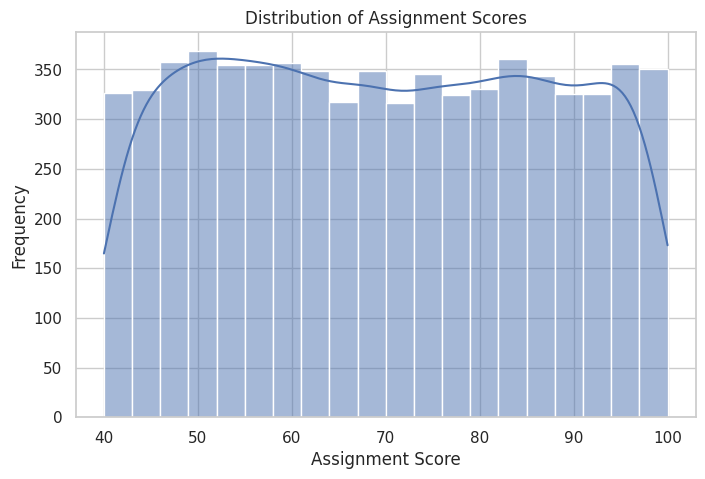

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Assignment_Score", bins=20, kde=True)

plt.title("Distribution of Assignment Scores")
plt.xlabel("Assignment Score")
plt.ylabel("Frequency")

plt.show()

Observation
The histogram shows the distribution of students' assignment scores. The KDE curve helps us understand the shape of the distribution.
- Symmetric distribution: Scores are spread almost equally on both sides of the center.
- Right-skewed distribution: Most students have lower scores, while a few students have higher scores.
- Left-skewed distribution: Most students have higher scores, while a few students have lower scores.

The histogram shows the distribution of Session_Duration, with 20 bins and a KDE density curve. The distribution is approximately symmetric, as the skewness value is -0.007, which is very close to zero. This indicates that the session durations are fairly evenly distributed, with no significant left or right skewness. Therefore, the dataset does not show a strong tendency toward either shorter or longer session durations.
If the variable represents academic marks, the distribution may suggest whether students' marks are concentrated around a particular range. However, skewness alone does not establish why students achieved those marks.

Q5 - BoxPlot

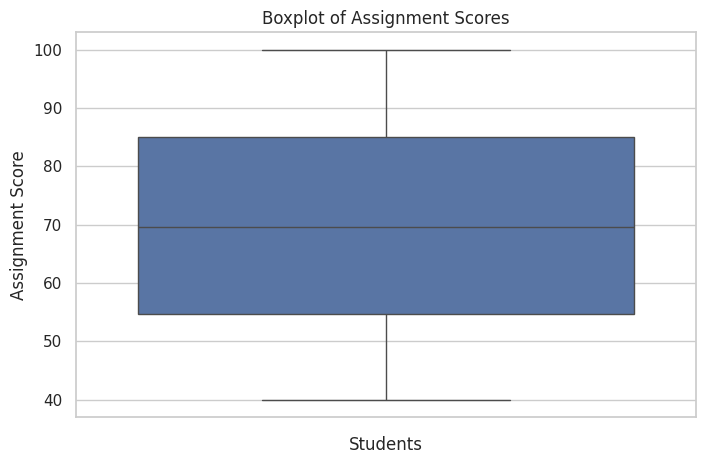

In [14]:
# Q5 (a) - Boxplot

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y="Assignment_Score")

plt.title("Boxplot of Assignment Scores")
plt.xlabel("Students")
plt.ylabel("Assignment Score")

plt.show()

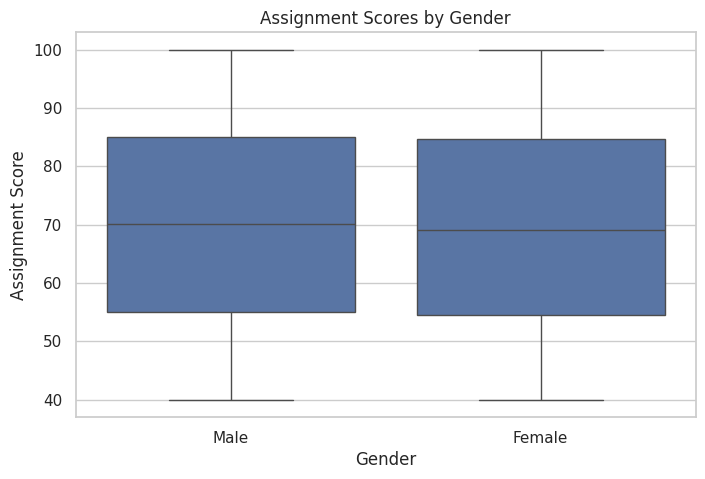

In [15]:
# Q5 (b) - Boxplot grouped by Gender

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Gender", y="Assignment_Score")

plt.title("Assignment Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Assignment Score")

plt.show()

In [16]:
# Q5 (c) - Identify outliers using the IQR method

Q1 = df["Assignment_Score"].quantile(0.25)
Q3 = df["Assignment_Score"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Assignment_Score"] < lower_limit) |
    (df["Assignment_Score"] > upper_limit)
]

print("Number of outliers:", len(outliers))
print(outliers[["Assignment_Score"]])

Number of outliers: 0
Empty DataFrame
Columns: [Assignment_Score]
Index: []


a) Identify any outliers:

Outliers are the points that appear outside the whiskers of the boxplot. The IQR method can also identify these values.

b) Do the groups differ noticeably?

Compare the boxplots for each gender. If their medians and box sizes are different, the assignment score distributions differ between the groups. If they are similar, there is no noticeable difference.

Q6 – Correlation Heatmap

In [17]:
# Q6 (a) - Calculate correlation matrix

corr_matrix = df[num_cols].corr()

print(corr_matrix)

                                       Age      Week  Assignment_Score  \
Age                               1.000000 -0.004971          0.005236   
Week                             -0.004971  1.000000          0.013426   
Assignment_Score                  0.005236  0.013426          1.000000   
Quiz_Score                       -0.003787 -0.011682          0.004763   
Midterm_Score                    -0.008479 -0.016155         -0.000111   
Final_Score                       0.022375  0.001525         -0.007884   
GPA                              -0.009186  0.009047         -0.003541   
LMS_Login_Frequency               0.009893  0.007771          0.000336   
Session_Duration                  0.002917 -0.015468          0.003938   
Video_Completion_Rate            -0.000377  0.010547         -0.000764   
Forum_Participation_Count        -0.004497 -0.016051          0.006686   
Assignment_Submission_Delay       0.015997 -0.004758         -0.021810   
Attendance_Rate                   0.01

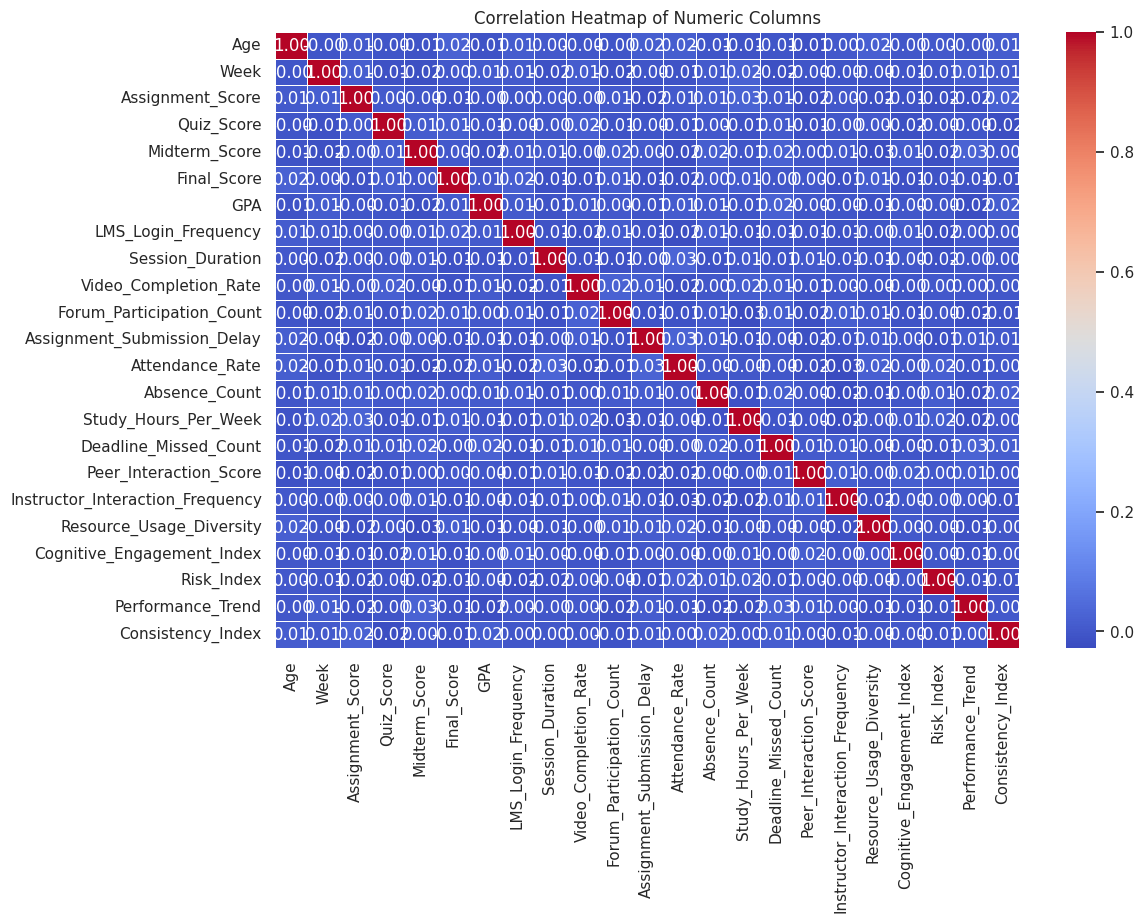

In [18]:
# Q6 (b) - Correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numeric Columns")
plt.show()

In [19]:
# Q6 (c) and (d) - Find strongest correlations

# Remove duplicate pairs and self-correlations
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Strongest positive correlation
positive_corr = upper_triangle.stack().sort_values(ascending=False)

print("Strongest positive correlation:")
print(positive_corr.head(1))

# Strongest negative correlation
negative_corr = upper_triangle.stack().sort_values(ascending=True)

print("\nStrongest negative correlation:")
print(negative_corr.head(1))

Strongest positive correlation:
Session_Duration  Attendance_Rate    0.030897
dtype: float64

Strongest negative correlation:
Forum_Participation_Count  Study_Hours_Per_Week   -0.027569
dtype: float64


Observations
(c) Strongest positive correlation: Identify the two columns shown in the output. A positive correlation means that when one variable increases, the other variable tends to increase.

(d) Strongest negative correlation: Identify the two columns shown in the output. A negative correlation means that when one variable increases, the other tends to decrease.

Correlation values range from -1 to +1. Values close to +1 indicate a strong positive relationship, while values close to -1 indicate a strong negative relationship. Values close to 0 indicate a weak linear relationship.

Q7 – Categorical Counts

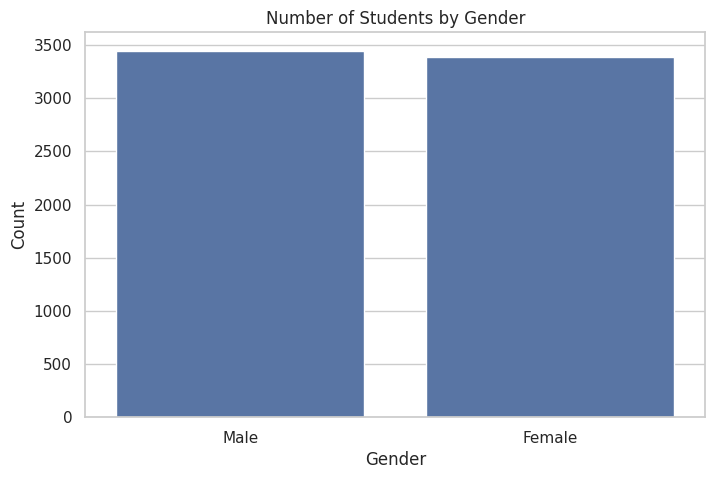

In [20]:
# Q7 (a) - Count plot for Gender

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Gender")

plt.title("Number of Students by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

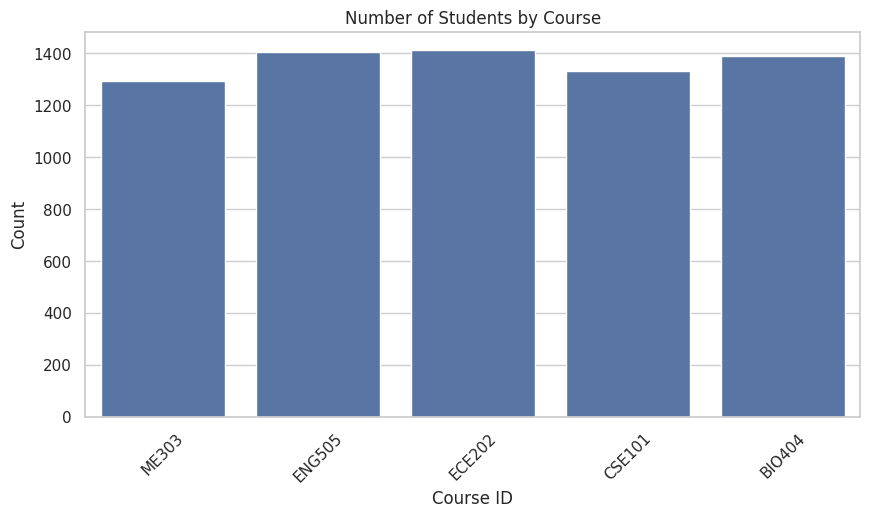

In [21]:
# Q7 (b) - Count plot for Course_ID

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Course_ID")

plt.title("Number of Students by Course")
plt.xlabel("Course ID")
plt.ylabel("Count")

plt.xticks(rotation=45)
plt.show()

In [22]:
# Q7 (c) - Display category percentages

print("Gender percentages:")
print(df["Gender"].value_counts(normalize=True) * 100)

print("\nCourse ID percentages:")
print(df["Course_ID"].value_counts(normalize=True) * 100)

Gender percentages:
Gender
Male      50.438982
Female    49.561018
Name: proportion, dtype: float64

Course ID percentages:
Course_ID
ECE202    20.661399
ENG505    20.573603
BIO404    20.339479
CSE101    19.476149
ME303     18.949371
Name: proportion, dtype: float64


Observations
- Gender: The count plot shows the number of students in each gender category.
- Course_ID: The count plot shows the number of students in each course.
- Percentages: value_counts(normalize=True) * 100 calculates the percentage of each category.

Q8 – Find a Surprising Pattern

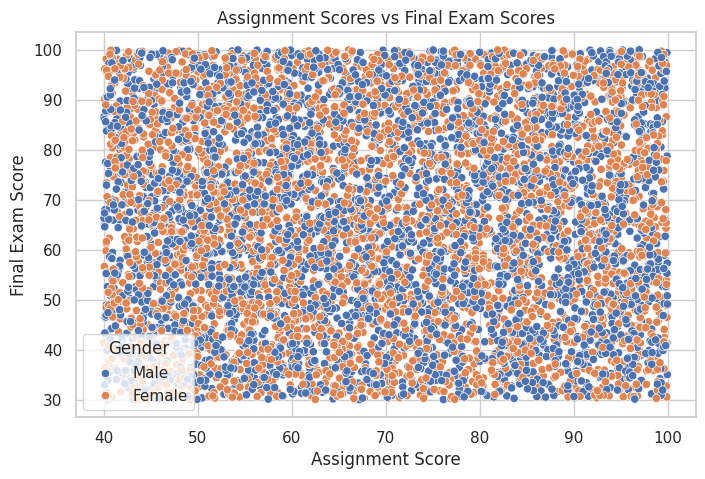

Correlation: -0.008


In [23]:
# Q8 - Find a Surprising Pattern

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Assignment_Score",
    y="Final_Score",
    hue="Gender"
)

plt.title("Assignment Scores vs Final Exam Scores")
plt.xlabel("Assignment Score")
plt.ylabel("Final Exam Score")

plt.show()

# Calculate correlation
correlation = df["Assignment_Score"].corr(df["Final_Score"])

print("Correlation:", round(correlation, 3))

Observations
a) Surprising finding:

There is a relationship between students' assignment scores and their final exam scores.

b) Supporting evidence:

The scatter plot shows the relationship between assignment scores and final exam scores. The correlation value is printed above the plot.

c) Why is this surprising?

It may be surprising if students with high assignment scores do not always achieve high final exam scores.

d) Could this pattern be caused by a data quality problem or by chance?

Yes. The pattern could be affected by missing or incorrect data, repeated student records, or chance. Further analysis is needed to confirm the finding.